Hyperparameter selection

* load GRF 100 instances
* load samples 100 instances
* run IDW
* set up hyperparameter search

In [1]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [2]:
import joblib
sphere_mesh = joblib.load(projdir + "/data/fsLR-4k_sphere_grf.pkl")

In [27]:
# create white noise
from numpy import random

noise = random.normal(0,1,4002)

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

def pink_noise(size, rand, roughness):
    white = rand(size=(size, size))
    white_ft = np.fft.fftshift(np.fft.fft2(white))

    hsize = size / 2
    y, x = np.ogrid[-hsize:hsize, -hsize:hsize]
    freq = (x**2 + y**2) ** (1 / roughness)
    pink_ft = np.divide(white_ft, freq,
      out=np.zeros_like(white_ft), where=freq!=0)

    pink = np.fft.ifft2(np.fft.ifftshift(pink_ft)).real
    lo, hi = np.min(pink), np.max(pink)
    return (pink - lo) / (hi - lo)

In [56]:
import numpy as np

# Example point cloud
points = sphere_mesh.points

# Extract coordinates
x = points[:, 0]
y = points[:, 1]
z = points[:, 2]

print(x.min())

-100.0


In [66]:

# Define sigma based on X position
sigma_min = .1
sigma_max = 1

sigma_map = sigma_min + (
    (x - x.min()) / (x.max() - x.min())
) * (sigma_max - sigma_min)

# Generate Gaussian noise
noise = np.random.normal(
    loc=0,
    scale=sigma_map,
    size=points.shape[0]
)

# Add noise to point cloud
#noisy_points = points + noise

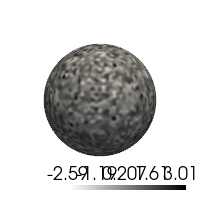

: 

In [ ]:
import pyvista as pv

pl = pv.Plotter(window_size = (200,200))

rng = np.random.default_rng(321)

pl.add_mesh(sphere_mesh, scalars=noise, cmap = 'gist_yarg')
pl.camera_position = 'yz'

pl.show(jupyter_backend = 'static')

In [3]:
from interpmodules import helpers

ran=25
nreps = 100

instances = [ helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=i) for i in range(nreps) ]

In [4]:
import time
def interpolate_IDW(X0, Y0, x1, power=2, timeit=False):
    '''
    X0: (N, 3) N-many sampled points, with x-y-z coordinates
    Y0: (N,) N-many sampled values at points X0
    
    x1: (n, 3) point to interpolate, with x-y-z coordinates
    '''

    if timeit: t1=time.process_time()

    Dist = helpers._get_distance_between(X0, x1)

    weights = 1 / (Dist**power)
    weights /= weights.sum(axis=0)
    y1 = np.dot(weights.T, Y0)
    y1[ np.where(np.isnan(y1))[0] ] = 0
    
    if timeit: t2=time.process_time(); return y1,t2-t1

    return y1

In [5]:
search_opts = np.linspace(0.1, 5.0, 50, dtype = np.float16)
print(search_opts)

[0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8
 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9 3.  3.1 3.2 3.3 3.4 3.5 3.6
 3.7 3.8 3.9 4.  4.1 4.2 4.3 4.4 4.5 4.6 4.7 4.8 4.9 5. ]


* Once

In [6]:
def run_param_tuning(iter, search_opts, data=None, sampl=None):
    
    from sklearn.metrics import root_mean_squared_error

    kc, kv, uc, uv = sampl[1]

    train = data[kv[:,iter].astype(int)]
    test = data[uv[:,iter].astype(int)]

    preds = np.zeros((nopts, uv.shape[0]))
    errors = np.zeros((nopts))
    times = np.zeros((nopts))
    
    for ind, pow in enumerate(search_opts):
        y1, t = interpolate_IDW(X0=kc[:,:,iter], x1=uc[:,:,iter], Y0=train, power=pow, timeit=True)
        preds[ind, :] = y1
        times[ind] = t

        errors[ind] = root_mean_squared_error(test, y1) / np.nanstd(test)

    return preds, errors, times


In [16]:
from joblib import Parallel, delayed

nreps = 1
niters = 100
nopts = len(search_opts)

sampl = joblib.load(projdir + "/data/sampling/fsLR-4k_sphere_samp-random_pct-50_iters-100.pkl")
kc, kv, uc, uv = sampl[1]

Preds = np.zeros((nreps, niters, nopts, uv.shape[0]))
Errors = np.zeros((nreps, niters, nopts))
Times = np.zeros((nreps, niters, nopts))

for rep in range(nreps):

    data = instances[rep]
    delayed_calls = Parallel(n_jobs=32, verbose=1)(delayed(run_param_tuning)(iter, search_opts, data, sampl) for iter in range(niters))

    for iter in range(niters):
        preds, errors, times = delayed_calls[iter]
        Preds[rep, iter, :, :] = preds
        Errors[rep, iter, :] = errors
        Times[rep, iter, :] = times

joblib.dump((ran, (Preds, Errors, Times)), "../results/rev_idw_power_tuning_pct-50.pkl")

#for iter in range(niters):

#    train = data[kv[:,iter].astype(int)]
#    test = data[uv[:,iter].astype(int)]

#    for ind, pow in enumerate(search_opts):
#        y1, t = interpolate_IDW(X0=kc[:,:,iter], x1=uc[:,:,iter], Y0=train, power=pow, timeit=True)
#        preds[:, ind, iter] = y1
#        times[iter, ind] = t

#        errors[iter, ind] = root_mean_squared_error(test, y1) / np.nanstd(test)


[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done 100 out of 100 | elapsed:  2.6min finished


['../results/rev_idw_power_tuning_pct-50.pkl']

# Visualization

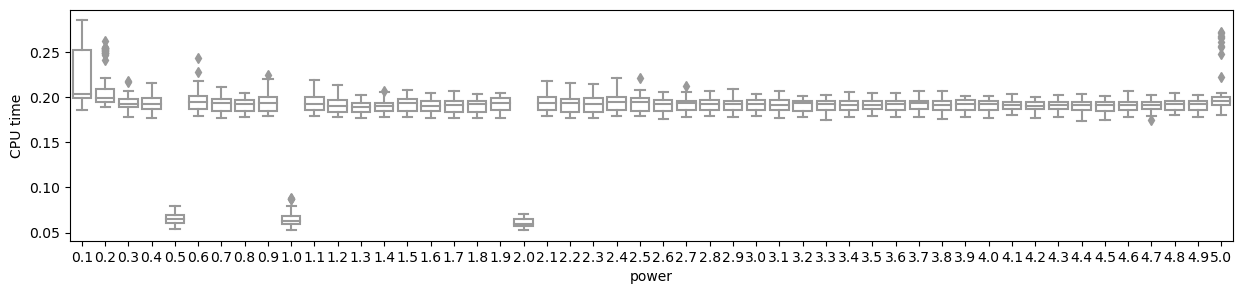

In [17]:
import pandas as pd
import seaborn as sns

df = pd.DataFrame(Times.reshape(-1,nopts), columns = np.round(search_opts, 2).astype(str))

plt.figure(figsize = (15,3))
sns.boxplot(df, color = 'w')
plt.ylabel("CPU time")
plt.xlabel("power")
plt.tight_layout; plt.show()

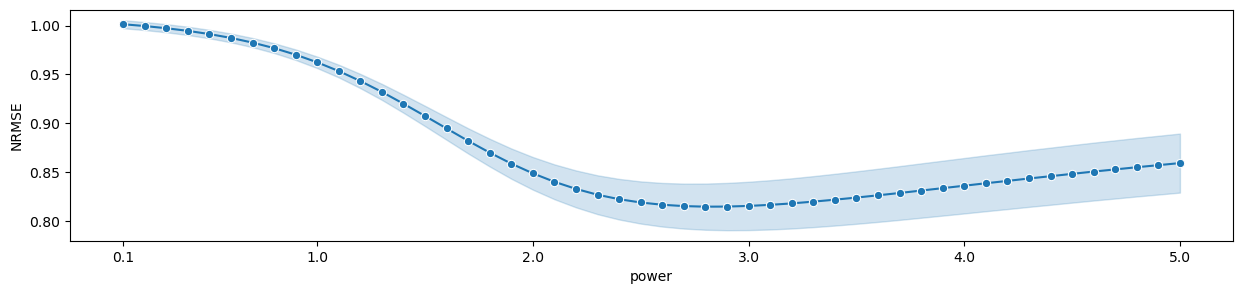

In [12]:
import seaborn as sns

df = pd.DataFrame(Errors.reshape(-1,nopts), columns = np.round(search_opts, 2).astype(str))
df_long = df.melt(
        var_name='power',
        value_name='error'
        )
plt.figure(figsize = (15,3))
sns.lineplot(df_long, x="power", y="error", style = 1, markers=True, errorbar='sd', legend=False)
plt.xticks([0, 9, 19, 29, 39, 49])
plt.ylabel("NRMSE")
plt.xlabel("power")
plt.tight_layout; plt.show()

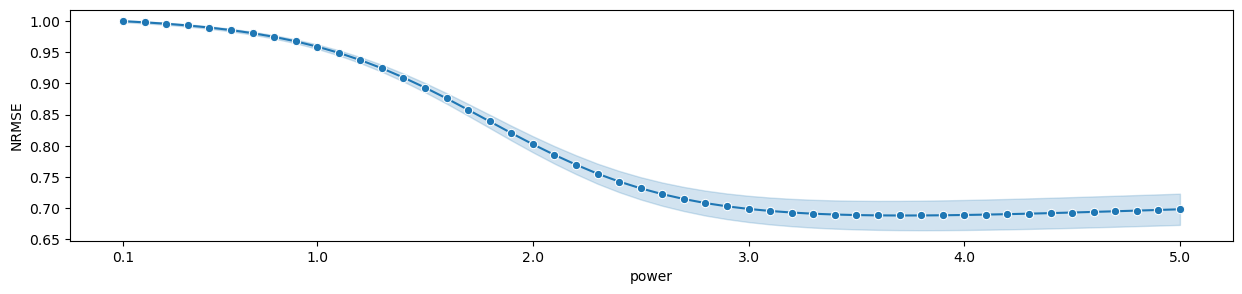

In [15]:
import seaborn as sns

df = pd.DataFrame(Errors.reshape(-1,nopts), columns = np.round(search_opts, 2).astype(str))
df_long = df.melt(
        var_name='power',
        value_name='error'
        )
plt.figure(figsize = (15,3))
sns.lineplot(df_long, x="power", y="error", style = 1, markers=True, errorbar='sd', legend=False)
plt.xticks([0, 9, 19, 29, 39, 49])
plt.ylabel("NRMSE")
plt.xlabel("power")
plt.tight_layout; plt.show()

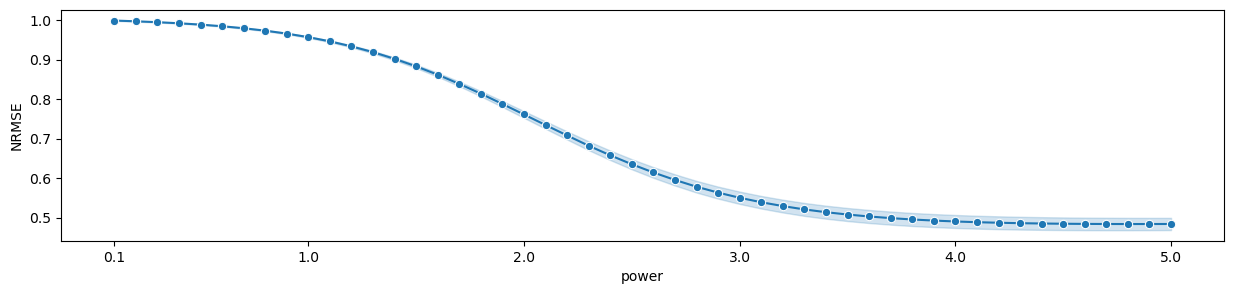

In [9]:
import seaborn as sns

df = pd.DataFrame(Errors.reshape(-1,nopts), columns = np.round(search_opts, 2).astype(str))
df_long = df.melt(
        var_name='power',
        value_name='error'
        )
plt.figure(figsize = (15,3))
sns.lineplot(df_long, x="power", y="error", style = 1, markers=True, errorbar='sd', legend=False)
plt.xticks([0, 9, 19, 29, 39, 49])
plt.ylabel("NRMSE")
plt.xlabel("power")
plt.tight_layout; plt.show()

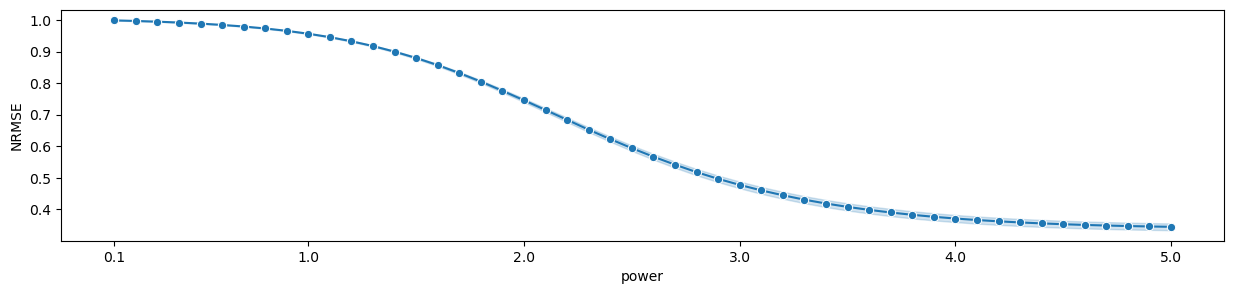

In [18]:
import seaborn as sns

df = pd.DataFrame(Errors.reshape(-1,nopts), columns = np.round(search_opts, 2).astype(str))
df_long = df.melt(
        var_name='power',
        value_name='error'
        )
plt.figure(figsize = (15,3))
sns.lineplot(df_long, x="power", y="error", style = 1, markers=True, errorbar='sd', legend=False)
plt.xticks([0, 9, 19, 29, 39, 49])
plt.ylabel("NRMSE")
plt.xlabel("power")
plt.tight_layout; plt.show()